# Classification de l'espèce d'un iris : KNN vs Arbre de décision

**Durée estimée : 1h**

## Mise en situation
Vous êtes data scientist chez **FloraLab**, un laboratoire de botanique. La direction veut un outil qui reconnaît **automatiquement l'espèce d'un iris** (Setosa, Versicolor, Virginica) à partir de quatre mesures, sans expert.


## Comment utiliser ce notebook
- Chaque section contient une **explication** (cellule texte) suivie d'une **cellule de code à compléter**.
- Les lignes `# TODO` indiquent ce qu'il faut écrire, avec un **indice** sur la fonction à utiliser.
- Les cellules **Interprétation** sont à remplir avec vos propres mots : c'est ce qui est évalué en plus du code.
- Exécutez les cellules **dans l'ordre**.

## 0. Imports et configuration
*Cette cellule est déjà remplie. Ajoutez des imports si nécessaire.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Exploration et analyse des données (EDA)

### 1.1 Chargement et structure
**But :** comprendre la forme.
**À faire :** llire le dataset, puis afficher `head()`, `shape`, `info()` et `describe()`.



In [2]:
df = sns.load_dataset("iris")
# TODO 1 : afficher head(), shape, info() et describe()

print(df.head())
# print("shape: " , df.shape)
# print(df.info())
# print(df.describe())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


### 1.2 Types de variables, valeurs manquantes et doublons
**But :** repérer les problèmes de qualité.
**À faire :** identifier variables numériques et catégorielles, compter les valeurs manquantes et les doublons, vérifier qu'aucune mesure n'est négative ou nulle.


In [3]:
# TODO : types, valeurs manquantes, doublons, valeurs impossibles
# df.dtypes
# df.isna().sum()
# df.duplicated().sum()


### 1.3 Équilibre des classes
**But :** savoir si l'accuracy sera une métrique fiable.
**À faire :** compter le nombre de fleurs par espèce et l'afficher dans un graphique en barres.


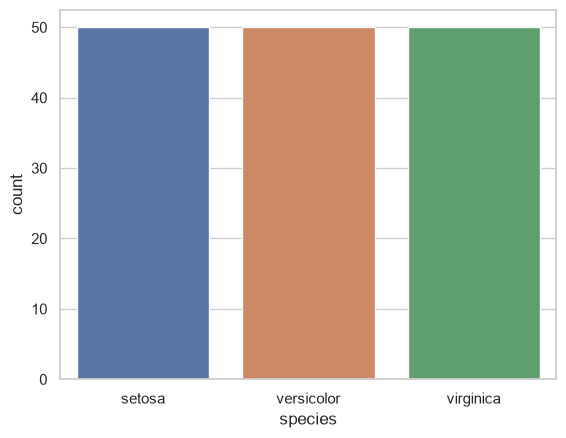

In [4]:
# TODO : value_counts + countplot ou graphique en barres

sns.countplot(data=df, x='species', hue='species')
plt.show()

### 1.4 Distributions des variables
**But :** comprendre la forme de chaque mesure.
**À faire :** tracer un histogramme et un boxplot pour une variable(s) numérique(s), puis un boxplot **par espèce**.


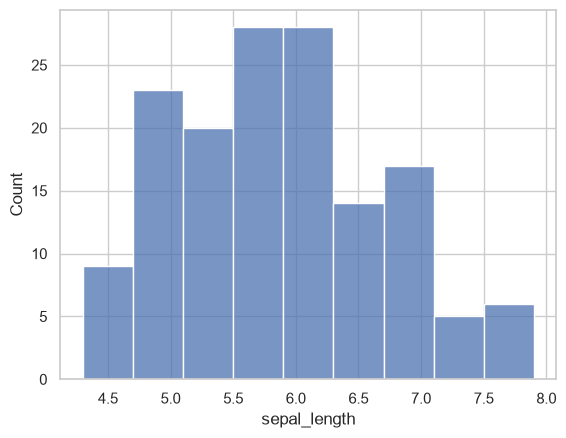

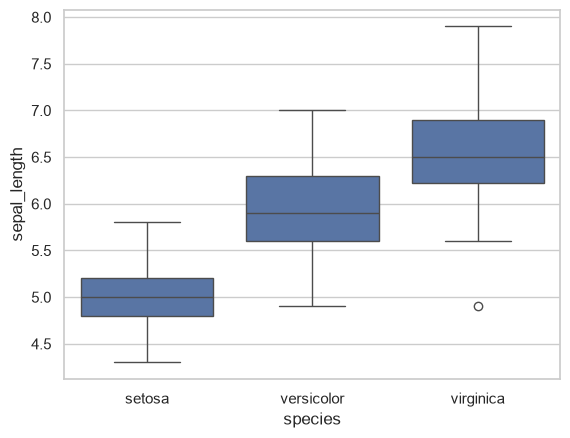

In [5]:
# TODO : histogrammes
# TODO : boxplots par espèce

sns.histplot(data=df, x='sepal_length')
plt.show()

sns.boxplot(data=df, x='species', y='sepal_length')
plt.show()

### 1.5 Corrélations
**But :** repérer les variables redondantes.
**À faire :** calculer la matrice de corrélation des 4 mesures et l'afficher en heatmap.


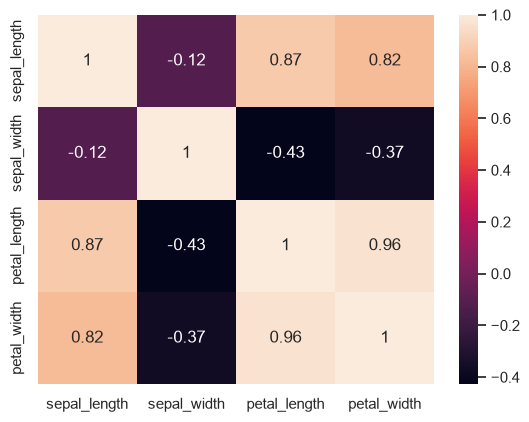

In [6]:
# TODO : matrice de corrélation + heatmap

sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

In [7]:
# TODO : nettoyage (doublons, valeurs manquantes, incohérences)
# TODO : vérification après nettoyage

df.drop_duplicates(inplace=True)
df.dropna(inplace=True)
df = df[df['sepal_length'] >= 0]
df = df[df['sepal_width'] >= 0]
df = df[df['petal_length'] >= 0]
df = df[df['petal_width'] >= 0]

df.duplicated().sum()
df.isna().sum()



sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

## 2. Nettoyage des données
**But :** obtenir un jeu de données fiable.
**À faire :**
1. Traiter les valeurs manquantes (s'il y en a).
2. Supprimer les doublons **seulement si c'est justifié**.
3. Corriger les valeurs impossibles.
4. Vérifier la qualité après nettoyage (shape, doublons, valeurs manquantes).


**Justification de vos décisions de nettoyage :**

...

## 3. Préparation des données
**But :** séparer ce qu'on veut prédire de ce qui sert à prédire.
**À faire :**
- Définir `y` (la cible : l'espèce).
- Définir `X` (les 4 mesures).
- Lister les variables numériques, nominales et ordinales.
- Écarter les identifiants ou variables non pertinentes.

In [8]:
# TODO : définir y
# TODO : définir X
# TODO : créer la liste num_features (variables numériques)
X = df.drop('species', axis=1)
y = df['species']
num_features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
target_feature = 'species'

## 4. Séparation Train / Test
**But :** garder un jeu de test totalement indépendant pour l'évaluation finale.
**À faire :** séparer en 80 % / 20 % avec `random_state` et `stratify=y`, puis vérifier la répartition des espèces dans chaque ensemble.

> Le split se fait **avant** tout apprentissage de transformation (sinon : fuite de données).

In [9]:
# TODO : X_train, X_test, y_train, y_test = train_test_split(...)
# TODO : afficher la répartition des espèces dans y_train et y_test

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(y_train.value_counts())
print(y_test.value_counts())

species
versicolor    41
setosa        40
virginica     38
Name: count, dtype: int64
species
virginica     11
setosa        10
versicolor     9
Name: count, dtype: int64


## 5. Prétraitement
**But :** préparer les transformations (sans encore les apprendre).
**À faire :**
- Créer un `ColumnTransformer` qui applique sur les variables numériques : `SimpleImputer(strategy='median')` puis `StandardScaler()`.
- Justifier l'absence d'`OneHotEncoder` et d'`OrdinalEncoder`.

In [ ]:
# TODO : numeric_transformer = Pipeline([...])
# TODO : preprocessor = ColumnTransformer([...])

numeric_transformer = Pipeline([
    ("SimpleImputer" , SimpleImputer(strategy='median')),
    ("StandardScaler" , StandardScaler()),
])


preprocessor = ColumnTransformer([
    ("numeric_transformer" , numeric_transformer , num_features)
])

# l'absence d'`OneHotEncoder` et d'`OrdinalEncoder` parce que ona des valeurs qui ont quantitative continue

## 6. Construction des pipelines
**But :** enchaîner prétraitement + modèle dans un seul objet, pour éviter toute fuite de données pendant la validation croisée.
**À faire :** créer ** le pipeline ** :
- `pipe_knn` : preprocessor + `KNeighborsClassifier()`

> Dans un `Pipeline`, donnez des noms aux étapes (par ex. `'prep'` et `'model'`) : vous en aurez besoin pour la grille d'hyperparamètres (`model__n_neighbors`).

In [54]:
# TODO : pipe_knn = Pipeline([...])

pipe_knn = Pipeline([
    ("preprocessor" , preprocessor),
    ("model" , KNeighborsClassifier())
])

## 7. Entraînement
**But :** obtenir une première version du modèle avec les hyperparamètres par défaut.

- **Algorithme 1 : KNN** — classe une fleur selon ses voisins les plus proches (modèle de référence).

**À faire :** entraîner le pipeline sur `X_train`, `y_train` et afficher l'accuracy sur le train.

In [55]:
# TODO : fit de pipe_knn
# TODO : afficher le score train de chacun (.score)
pipe_knn.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['setosa','versicolor','virginica']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['sepal_length','sepal_width','petal_length','petal_width']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric_transformer', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

## 8. Validation croisée
**But :** estimer la performance de façon fiable.
**À faire :**
- Créer `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)`.
- Calculer les scores de chaque pipeline avec `cross_val_score` (métrique `accuracy`, puis `f1_macro`).
- Afficher la **moyenne** des scores.


In [56]:
# TODO : cv = StratifiedKFold(...)
# TODO : scores accuracy et f1_macro pour pipe_knn
# TODO : afficher moyenne

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scores_accuracy = cross_val_score(pipe_knn, x_train, y_train, cv=cv, scoring='accuracy')
scores_f1_macro = cross_val_score(pipe_knn, x_train, y_train, cv=cv, scoring='f1_macro')
print("Accuracy: ", scores_accuracy.mean()) 
print("F1 macro: ", scores_f1_macro.mean())


Accuracy:  0.9414529914529915
F1 macro:  0.9408085639719822


## 9. Optimisation des hyperparamètres (GridSearchCV)
**But :** trouver les meilleurs réglages.
**À faire :** définir une grille pour ton pipeline, lancer `GridSearchCV(..., cv=cv, scoring='f1_macro')` et afficher `best_params_` et `best_score_`.

Grilles suggérées :
- **KNN** : `model__n_neighbors` (2 à 5), `model__weights` (`uniform`, `distance`), `model__p` (1, 2).
> Le préfixe `model__` correspond au nom de l'étape dans votre pipeline.
> Le GridSearch ne doit utiliser que `X_train` et `y_train`.

In [ ]:
# TODO : param_grid_knn
# TODO : grid_knn = GridSearchCV(...) puis fit sur le train
# TODO : afficher best_params_ et best_score_

param_grid_knn = {
    'model__n_neighbors': [2, 3, 4, 5],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]
}
grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=cv, scoring='f1_macro')

# print(grid_knn.)

grid_knn.fit(x_train , y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__n_neighbors': [2, 3, ...], 'model__p': [1, 2], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",T

## 10. Évaluation sur le jeu de test
**But :** mesurer la performance réelle sur des données jamais vues.
**À faire :** pour chaque meilleur modèle (`best_estimator_`) :
1. Prédire sur `X_test`.
2. Calculer accuracy, précision (macro), rappel (macro) et F1 (macro).
3. Afficher la **matrice de confusion** et le `classification_report`.
4. Donner les valeurs ( TP , FP , TN , FN) pour chaque classe .

Rappel des métriques :
- **Accuracy** : proportion de fleurs bien classées.
- **Précision** : parmi les fleurs prédites d'une espèce, combien le sont vraiment.
- **Rappel** : parmi les fleurs réellement d'une espèce, combien sont retrouvées.
- **F1 macro** : moyenne du F1 des trois espèces, à égalité.

> Le jeu de test ne doit servir qu'ici, une seule fois.

In [75]:
# TODO : best_knn = grid_knn.best_estimator_
# TODO : prédictions sur X_test
# TODO : métriques (accuracy, precision, recall, f1 avec average='macro')
# TODO : matrices de confusion (ConfusionMatrixDisplay.from_estimator)
# TODO : classification_report

best_knn = grid_knn.best_estimator_
y_pred = best_knn.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')

# precision
accuracy
# recall
# f1

1.0